# Week 8 — Evaluating closing-price predictions

**Goal:** Evaluate the fixed Week 7 predictions beyond R² using MAPE and MdAPE, compare performance overall and across price bands, and summarize where each model is more or less accurate. Deliverables are this notebook and `artifacts/week8/metrics_summary.csv`.

Central Questions: **How large are the errors relative to a home's price? Which price bands does each model predict most accurately? Does the model with the best overall score also perform well across bands?**

This notebook evaluates the same April homes for Random Forest, starter XGBoost, and tuned XGBoost. It adds no model fitting or hyperparameter tuning. April was inspected in earlier weeks; these results expand the historical comparison rather than provide a new independent test.

## 1. Load the evaluation snapshot

Use the **Week 8 handoff** cell after the April comparison in `05_advanced_models.ipynb` to save its existing April predictions. Aggregate Week 7 JSON scores alone cannot recover MAPE or MdAPE: those require the individual actual and predicted prices.

The handoff creates `april_evaluation_predictions.npz` and its manifest under `artifacts/week7/`. This notebook reads those files independently and verifies their content hash, row alignment, and original MAE/RMSE/R². No CSV input or model package is needed for evaluation.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

project_root = next((parent for parent in (Path.cwd(), *Path.cwd().parents)
                     if (parent / "notebooks" / "05_advanced_models.ipynb").is_file()), None)
if project_root is None:
    raise FileNotFoundError("Start in the project root or notebooks directory.")
bundle_path = project_root / "artifacts" / "week7" / "april_evaluation_predictions.npz"
manifest_path = bundle_path.with_name("april_evaluation_manifest.json")
if not bundle_path.exists() or not manifest_path.exists():
    raise FileNotFoundError("Run the Week 8 handoff cell after the April comparison in 05_advanced_models.ipynb first.")
manifest = json.loads(manifest_path.read_text())
assert hashlib.sha256(bundle_path.read_bytes()).hexdigest() == manifest["bundle_sha256"], "Evaluation snapshot hash mismatch."
with np.load(bundle_path, allow_pickle=False) as bundle:
    actual = bundle["actual"].copy()
    predictions = bundle["predictions"].copy()
    model_names = bundle["model_names"].astype(str).tolist()
    listing_keys = bundle["listing_keys"].astype(str).copy()
    sale_dates = pd.to_datetime(bundle["sale_dates"].astype(str), errors="raise")


## 2. Confirm the models are evaluated on the same homes

The snapshot has one row per listing, one actual price, and a prediction column for each model. All prices must be finite and actual prices positive for percentage errors. Nonpositive predictions remain in the evaluation and are counted rather than clipped or removed.


In [2]:
assert actual.ndim == 1 and len(actual) >= 2
assert predictions.shape == (len(actual), len(model_names))
assert len(model_names) == len(set(model_names)) and model_names == manifest["model_names"]
assert len(actual) == manifest["rows"] == len(listing_keys) == len(sale_dates)
assert pd.Index(listing_keys).is_unique and pd.Series(listing_keys).str.strip().ne("").all()
assert np.isfinite(actual).all() and (actual > 0).all()
assert np.isfinite(predictions).all()
assert sale_dates.notna().all() and (sale_dates.to_period("M").astype(str) == manifest["test_month"]).all()
reference_metrics = pd.DataFrame(manifest["reference_test_metrics"]).set_index("model")
for column, model_name in enumerate(model_names):
    predicted = predictions[:, column]
    calculated = [mean_absolute_error(actual, predicted), np.sqrt(mean_squared_error(actual, predicted)), r2_score(actual, predicted)]
    expected = reference_metrics.loc[model_name, ["test_mae_usd", "test_rmse_usd", "test_r2"]].to_numpy(dtype=float)
    assert np.allclose(calculated, expected, rtol=1e-8, atol=1e-6), f"Snapshot differs from Week 7: {model_name}"
print(f"Verified {len(actual):,} shared sales from {manifest['test_month']} for {len(model_names)} models.")
display(pd.DataFrame({"model": model_names,
                      "nonpositive_predictions": [(predictions[:, column] <= 0).sum() for column in range(len(model_names))]}))
print("Actual-price range:", f"${actual.min():,.2f} to ${actual.max():,.2f}")


Verified 12,480 shared sales from 2026-04 for 3 models.


,model,nonpositive_predictions
0,Random Forest: Week 6 features,0
1,XGBoost: starter,0
2,XGBoost: validation-selected,1


Actual-price range: $50,000.00 to $60,000,000.00


### First review

Confirm that the row count, models, and MAE/RMSE/R² match Week 7. A mismatch should be resolved before interpreting new metrics. The checks above do not independently validate the source sale prices.

## 3. Define MAPE and MdAPE

For each sale, **absolute percentage error (APE) = 100 × |actual − predicted| / actual**.

- **MAPE** is the mean APE: average percentage error across sales.
- **MdAPE** is the median APE: the middle percentage error. A lower MdAPE means lower error for the median sale, not necessarily every sale.
- MAE and RMSE retain the dollar-error context; R² stays in the overall comparison.

A $900,000 prediction for a $1 million sale has a 10% APE. MAPE can be dominated by low actual prices; MdAPE is less sensitive to extreme individual errors. All percentage columns below use **percentage points** (10 means 10%), not decimal fractions. The calculation is mean of individual percentage errors, not MAE divided by mean price.

Reference: [scikit-learn MAPE documentation](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.mean_absolute_percentage_error.html).


In [3]:
def evaluation_metrics(actual_prices, predicted_prices):
    observed = np.asarray(actual_prices, dtype=float)
    estimated = np.asarray(predicted_prices, dtype=float)
    if observed.ndim != 1 or estimated.shape != observed.shape:
        raise ValueError("Actual and predicted prices must be aligned one-dimensional arrays.")
    if not np.isfinite(observed).all() or not np.isfinite(estimated).all() or (observed <= 0).any():
        raise ValueError("Use finite values and strictly positive actual prices; do not silently drop records.")
    if len(observed) == 0:
        return dict(rows=0, mae_usd=np.nan, rmse_usd=np.nan, r2=np.nan,
                    mape_pct=np.nan, mdape_pct=np.nan, mean_residual_usd=np.nan)
    residual = observed - estimated
    ape = 100 * np.abs(residual) / observed
    return {
        "rows": len(observed), "mae_usd": float(np.mean(np.abs(residual))),
        "rmse_usd": float(np.sqrt(np.mean(residual ** 2))),
        "r2": float(r2_score(observed, estimated)) if len(observed) >= 2 and np.ptp(observed) > 0 else np.nan,
        "mape_pct": float(np.mean(ape)), "mdape_pct": float(np.median(ape)),
        "mean_residual_usd": float(np.mean(residual)),
    }

# Calculation check: individual APEs are 10%, 10%, and 20%.
example = evaluation_metrics([100, 200, 1000], [90, 180, 1200])
assert np.isclose(example["mape_pct"], 40 / 3)
assert np.isclose(example["mdape_pct"], 10)
print("Example MAPE:", round(example["mape_pct"], 2), "% | MdAPE:", round(example["mdape_pct"], 2), "%")


Example MAPE: 13.33 % | MdAPE: 10.0 %


### Metric checkpoint

The example should report **MAPE 13.33% and MdAPE 10.00%**. These definitions and the snapshot checks are the first review point. The remaining sections are prepared so the analysis can continue after that check.

## 4. Compare overall model performance

Evaluate all models on every shared April sale. Keep the starter XGBoost as context for tuning; focus the model-choice discussion on Random Forest and tuned XGBoost. The table shows exact values; separate percentage-error charts keep MAPE from obscuring MdAPE when their scales differ.


,model,scope,price_band,test_month,rows,mae_usd,rmse_usd,r2,mape_pct,mdape_pct,mean_residual_usd
0,Random Forest: Week 6 features,overall,All sales,2026-04,12480,241294.6381,859906.9641,0.6962,15.7468,9.2316,41269.9069
1,XGBoost: starter,overall,All sales,2026-04,12480,327353.1294,878503.6641,0.6829,26.8056,17.9076,34908.6611
2,XGBoost: validation-selected,overall,All sales,2026-04,12480,251189.0882,811824.7092,0.7292,18.4281,12.2815,25893.0343


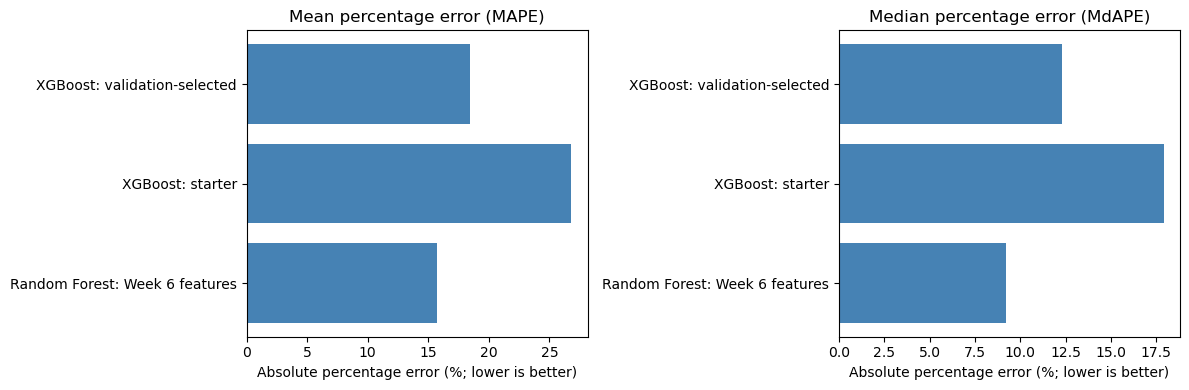

In [4]:
overall_metrics = pd.DataFrame([
    {"model": name, "scope": "overall", "price_band": "All sales", "test_month": manifest["test_month"],
     **evaluation_metrics(actual, predictions[:, column])}
    for column, name in enumerate(model_names)
])
display(overall_metrics.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, title in zip(axes, ["mape_pct", "mdape_pct"], ["Mean percentage error (MAPE)", "Median percentage error (MdAPE)"]):
    values = overall_metrics.set_index("model")[metric]
    ax.barh(values.index, values.to_numpy(), color="steelblue")
    ax.set(title=title, xlabel="Absolute percentage error (%; lower is better)")
fig.tight_layout()
plt.show()


Random Forest led on absolute and percentage errors, while tuned XGBoost led on RMSE and R².

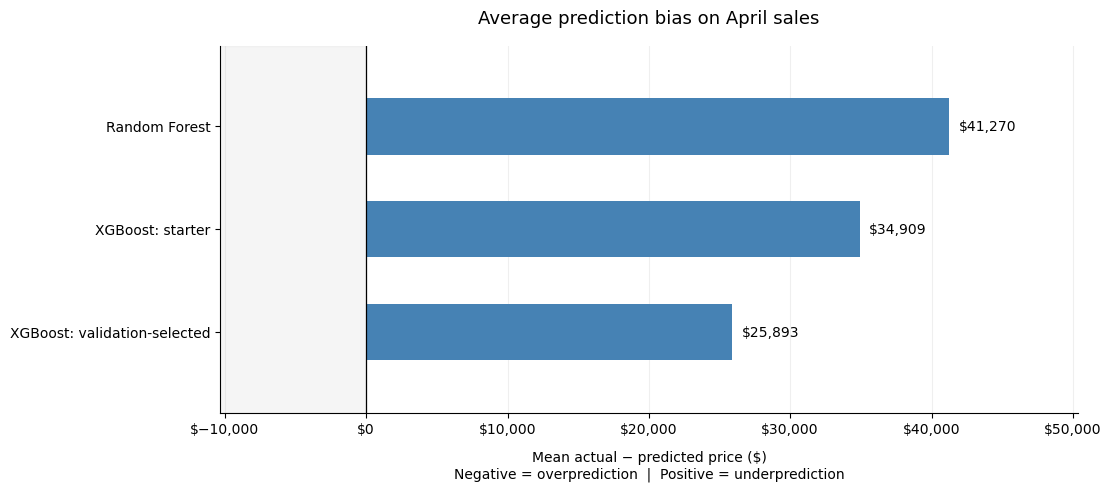

In [11]:
# Signed residual: actual price minus predicted price.
from matplotlib.ticker import StrMethodFormatter

mean_residuals = overall_metrics.set_index("model")["mean_residual_usd"]
plot_labels = ["Random Forest" if name == "Random Forest: Week 6 features" else name
               for name in mean_residuals.index]
fig, ax = plt.subplots(figsize=(11, 4.8), layout="constrained")
bars = ax.barh(plot_labels, mean_residuals.to_numpy(), height=.55,
               color=["steelblue" if value >= 0 else "darkorange" for value in mean_residuals])
ax.invert_yaxis()
ax.axvline(0, color="black", linewidth=.9)
ax.bar_label(bars, labels=[f"${value:,.0f}" if value >= 0 else f"−${abs(value):,.0f}"
                          for value in mean_residuals], padding=7, fontsize=10)
# Include a small negative range to show the direction around zero.
minimum, maximum = float(mean_residuals.min()), float(mean_residuals.max())
span = max(abs(minimum), abs(maximum), 1)
ax.set_xlim(minimum - .22 * span if minimum < 0 else -.25 * span,
            maximum + .22 * span if maximum > 0 else .22 * span)
ax.axvspan(ax.get_xlim()[0], 0, color="gray", alpha=.08, zorder=0)
ax.xaxis.set_major_formatter(StrMethodFormatter("${x:,.0f}"))
ax.set_title("Average prediction bias on April sales", fontsize=13, pad=16)
ax.set_xlabel("Mean actual − predicted price ($)\nNegative = overprediction  |  Positive = underprediction", labelpad=10)
ax.set_ylabel("")
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=.2)
ax.spines[["top", "right"]].set_visible(False)
ax.margins(y=.2)
plt.show()


**All three models underpredict on average in dollars.** Their mean residuals are positive: approximately **$41,270 for Random Forest**, **$34,909 for starter XGBoost**, and **$25,893 for validation-selected XGBoost**. Tuned XGBoost has the smallest mean underprediction in this comparison.

This is a signed average, not the average absolute error. It does not mean every home—or most homes—was underpredicted; overpredictions and underpredictions can offset each other. This identifies a directional bias worth investigating by price band. The analysis below checks whether average underprediction is concentrated in particular price ranges or appears across them.

### Overall findings

Comparing the three model configurations from Week 7 on the same **12,480 April sales**, no single model performed best across MAPE, MdAPE, and R². **Random Forest had the lowest MAPE and MdAPE**, while **validation-selected XGBoost had the highest R²**. The selected XGBoost improved on the starter across all three measures, but did not outperform Random Forest on percentage errors.

| Model | MAPE ↓ | MdAPE ↓ | R² ↑ |
| --- | ---: | ---: | ---: |
| Random Forest: Week 6 features | **15.75%** | **9.23%** | 0.6962 |
| XGBoost: starter | 26.81% | 17.91% | 0.6829 |
| XGBoost: validation-selected | 18.43% | 12.28% | **0.7292** |

**What “validation-selected” means.** Eight XGBoost configurations were compared using January→February and January–February→March validation. The configuration with the lowest equal-weight mean monthly validation MAE was selected: **maximum depth 6, learning rate 0.1, and 500 trees**. It was then refitted on January–March sales and evaluated on April. “Selected” refers to its hyperparameters, not a different set of features or selection using April results. The starter used depth 3, learning rate 0.1, and 200 trees; Random Forest used 100 trees with no depth limit and minimum leaf size 1.

**Features used by each model.** All three configurations use the same **14 predictors**, so the comparison holds model inputs constant:

| Feature group | Predictors | Used by |
| --- | --- | --- |
| Property characteristics | LivingArea, LotSizeSquareFeet, BedroomsTotal, BathroomsTotalInteger, GarageSpaces, Stories, YearBuilt | All three models |
| Location | Latitude, Longitude, City, PostalCode | All three models |
| Engineered geographic layer | ElementaryDistrictCode, HighDistrictCode, UnifiedDistrictCode | All three models |

ParkingTotal is excluded. Log sizes, bed/bath ratio, living area per bedroom, and property age are not inputs to these April predictions. Those were evaluated separately in Week 7's later validation experiments; they did not replace the original model comparison.

**Interpreting the errors.** Random Forest's MdAPE of **9.23%** means half of these sales had an absolute percentage error at or below approximately 9.23%. Tuned XGBoost's MdAPE was **12.28%**. Random Forest also had lower MAE (**$241,295 versus $251,189**), while tuned XGBoost had lower RMSE (**$811,825 versus $859,907**). The latter's higher R² and lower RMSE indicate better squared-error performance, rather than uniformly better predictions.

MAPE exceeds MdAPE for every model, indicating that larger percentage errors pull the mean upward. The sensitivity analysis below checks whether low recorded prices or a small number of extreme errors drive that difference. All three models have positive mean residuals (actual minus predicted), indicating average underprediction in dollars: about **$41,270** for Random Forest, **$34,909** for starter XGBoost, and **$25,893** for tuned XGBoost. This signed average can conceal offsetting errors, so the next section examines price bands.

These results expand a previously inspected historical test comparison. They support a metric-specific tradeoff and do not provide an independent future-performance confirmation.

## 5. Compare the same price bands for every model

Using four fixed, interpretable bands: **up to $500k**, **over $500k–$1m**, **over $1m–$2m**, and **over $2m**. Bands are based on actual close price and use identical properties for all models. These are reporting categories, not learned cutoffs or new model inputs.

Bands describe where predictions work well; an unknown home's final sale price would not be available to route it to a model in an app.


,sales
Up to $500k,1797
Over $500k–$1m,5166
Over $1m–$2m,3765
Over $2m,1752


,model,scope,price_band,test_month,rows,mae_usd,rmse_usd,r2,mape_pct,mdape_pct,mean_residual_usd,small_group_under_30
0,Random Forest: Week 6 features,price_band,Up to $500k,2026-04,1797,7.406892e+04,1.739844e+05,-3.0490,23.2557,9.6685,-49941.9704,False
1,XGBoost: starter,price_band,Up to $500k,2026-04,1797,1.774843e+05,2.571447e+05,-7.8448,53.8835,34.2225,-149462.9644,False
2,XGBoost: validation-selected,price_band,Up to $500k,2026-04,1797,1.014599e+05,1.774186e+05,-3.2105,30.9657,16.6723,-67661.0106,False
3,Random Forest: Week 6 features,price_band,Over $500k–$1m,2026-04,5166,8.962527e+04,1.539640e+05,-0.2383,12.0218,7.1947,-37132.3991,False
4,XGBoost: starter,price_band,Over $500k–$1m,2026-04,5166,1.657757e+05,2.436233e+05,-2.1005,22.9221,15.4597,-112840.4601,False
5,XGBoost: validation-selected,price_band,Over $500k–$1m,2026-04,5166,1.123250e+05,1.701593e+05,-0.5125,15.2816,10.4601,-47092.5302,False
6,Random Forest: Week 6 features,price_band,Over $1m–$2m,2026-04,3765,2.170722e+05,3.590105e+05,-0.7010,15.2316,10.4791,-20749.4645,False
7,XGBoost: starter,price_band,Over $1m–$2m,2026-04,3765,2.880452e+05,4.104206e+05,-1.2230,20.1450,15.7788,30500.4652,False
8,XGBoost: validation-selected,price_band,Over $1m–$2m,2026-04,3765,2.299923e+05,3.637419e+05,-0.7461,16.1367,12.1562,-1886.9282,False
9,Random Forest: Week 6 features,price_band,Over $2m,2026-04,1752,9.120857e+05,2.211181e+06,0.4870,20.1358,15.2184,499281.8876,False


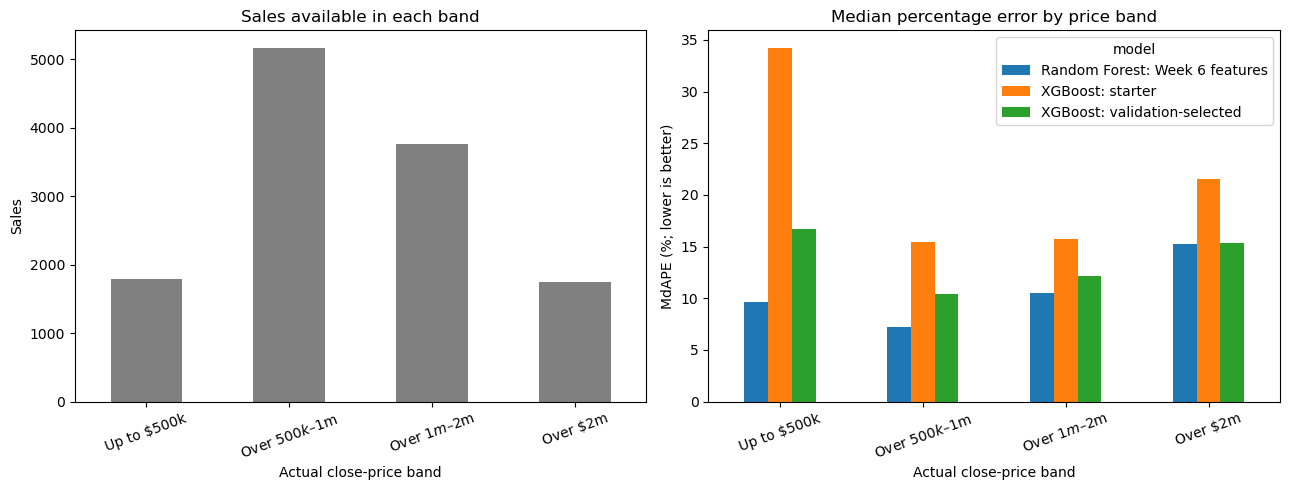

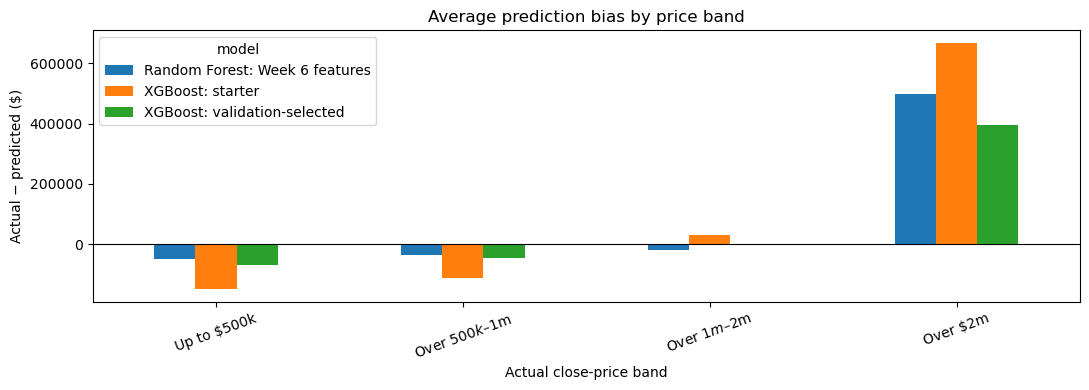

In [13]:
BAND_EDGES = [0, 500_000, 1_000_000, 2_000_000, np.inf]
BAND_LABELS = ["Up to $500k", "Over $500k–$1m", "Over $1m–$2m", "Over $2m"]
price_bands = pd.cut(actual, bins=BAND_EDGES, labels=BAND_LABELS, right=True, include_lowest=True)
assert not pd.isna(price_bands).any()
band_counts = pd.Series(price_bands).value_counts(sort=False).reindex(BAND_LABELS, fill_value=0)
display(band_counts.rename("sales").to_frame())

band_rows = []
for band in BAND_LABELS:
    mask = np.asarray(price_bands == band)
    for column, name in enumerate(model_names):
        band_rows.append({"model": name, "scope": "price_band", "price_band": band,
                          "test_month": manifest["test_month"],
                          **evaluation_metrics(actual[mask], predictions[mask, column])})
band_metrics = pd.DataFrame(band_rows)
band_metrics["small_group_under_30"] = band_metrics["rows"].lt(30)
assert band_metrics.groupby("model")["rows"].sum().eq(len(actual)).all()
display(band_metrics.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
band_counts.plot.bar(ax=axes[0], color="gray", rot=20)
axes[0].set(title="Sales available in each band", ylabel="Sales", xlabel="Actual close-price band")
band_metrics.pivot(index="price_band", columns="model", values="mdape_pct").reindex(BAND_LABELS).plot.bar(ax=axes[1], rot=20)
axes[1].set(title="Median percentage error by price band", ylabel="MdAPE (%; lower is better)", xlabel="Actual close-price band")
fig.tight_layout()
plt.show()

# Positive mean residual indicates underprediction; negative indicates overprediction.
band_metrics.pivot(index="price_band", columns="model", values="mean_residual_usd").reindex(BAND_LABELS).plot.bar(figsize=(11, 4), rot=20)
plt.axhline(0, color="black", linewidth=.8)
plt.title("Average prediction bias by price band")
plt.ylabel("Actual − predicted ($)")
plt.xlabel("Actual close-price band")
plt.tight_layout()
plt.show()


**Price Bands:** All models achieved their lowest median percentage error between $500k and $1m. Random Forest had lower MdAPE in every band. Above $2m, tuned XGBoost had lower MAE, RMSE, and MAPE, showing that the preferred model depends on the error measure.

**Directional bias:** The models overpredicted on average below $1m and underpredicted above $2m. Large dollar underpredictions among expensive homes outweighed lower-band overpredictions, explaining the overall underprediction.


### Price-band findings

**Accuracy is strongest in the $500k–$1m band.** All three models achieved their lowest MdAPE in this band, which contains **5,166 sales**, the largest evaluation group. Random Forest achieved MdAPE **7.19%**, compared with **10.46%** for validation-selected XGBoost and **15.46%** for starter XGBoost. Each band contains at least 1,752 sales; none meets the small-group flag used in this analysis.

| Actual close-price band | Sales | Random Forest MdAPE | Selected XGBoost MdAPE |
| --- | ---: | ---: | ---: |
| Up to $500k | 1,797 | **9.67%** | 16.67% |
| Over $500k–$1m | 5,166 | **7.19%** | 10.46% |
| Over $1m–$2m | 3,765 | **10.48%** | 12.16% |
| Over $2m | 1,752 | **15.22%** | 15.30% |

**Random Forest has the lowest median percentage error in every band.** It also has lower MAE, RMSE, and MAPE than both XGBoost configurations in the three bands at or below $2m. The MdAPE difference between Random Forest and selected XGBoost above $2m is small (approximately 0.08 percentage points); no statistical significance is claimed.

**Selected XGBoost performs better on aggregate errors above $2m.** Its MAE is **$859,774**, compared with **$912,086** for Random Forest; RMSE is **$2,071,879 versus $2,211,181**, and MAPE is **19.77% versus 20.14%**. Random Forest retains a slightly lower MdAPE. The improved high-price squared-error performance is consistent with selected XGBoost's lower overall RMSE and higher R², despite its higher overall MAE.

**Bias changes direction across price bands.** Every model overpredicts on average in the two bands at or below $1m and underpredicts on average above $2m. Random Forest and selected XGBoost also have negative mean residuals in the $1m–$2m band, while starter XGBoost has a positive mean residual there.

| Actual close-price band | Random Forest mean residual | Selected XGBoost mean residual |
| --- | ---: | ---: |
| Up to $500k | −$49,942 | −$67,661 |
| Over $500k–$1m | −$37,132 | −$47,093 |
| Over $1m–$2m | −$20,749 | −$1,887 |
| Over $2m | +$499,282 | +$396,756 |

Residuals are actual minus predicted price: negative values indicate average overprediction and positive values indicate average underprediction. The substantial dollar underprediction above $2m outweighs average overprediction in the lower bands, explaining the positive overall mean residuals. Near-zero signed bias does not imply low individual error: selected XGBoost's mean residual in the $1m–$2m band is approximately **−$1,887**, while its MAE is approximately **$229,992**.

**Interpretation and limitations.** Random Forest remains the stronger model for median percentage accuracy in this sample, while selected XGBoost offers better aggregate dollar-error performance above $2m. Within-band R² is sensitive to restricted price variation and is not used to rank accuracy across bands. These are descriptive results from a previously inspected April sample; actual-price bands are evaluation categories, not information available to select a model for an unsold property. Further temporal evaluation is needed to establish whether these patterns persist.

## 6. Check whether low prices dominate MAPE

Report the full-data result first. As an explicit diagnostic, compare it with sales at or above **$100,000**. This fixed threshold is an illustration of denominator sensitivity, not a new cleaning rule or a claim that every cheaper sale is invalid. Both subsets remain visible; the deliverable table continues to include all sales.

The share of total APE contributed by the largest 1% of errors provides another concentration check. If a few observations dominate MAPE, report that alongside MdAPE and dollar errors. Investigate source records separately before making any exclusion decisions.


In [14]:
SENSITIVITY_PRICE_FLOOR = 100_000
sensitivity_rows = []
for column, name in enumerate(model_names):
    ape = 100 * np.abs(actual - predictions[:, column]) / actual
    top_count = max(1, int(np.ceil(.01 * len(ape))))
    top_share = 100 * np.sort(ape)[-top_count:].sum() / ape.sum() if ape.sum() else 0.0
    retained = actual >= SENSITIVITY_PRICE_FLOOR
    for label, mask in [("All sales", np.ones(len(actual), dtype=bool)),
                         ("Sensitivity only: actual >= $100k", retained)]:
        sensitivity_rows.append({"model": name, "sample": label,
                                 **evaluation_metrics(actual[mask], predictions[mask, column]),
                                 "top_1pct_ape_share_full_sample_pct": float(top_share)})
sensitivity_metrics = pd.DataFrame(sensitivity_rows)
print(f"Sales below the diagnostic threshold: {(actual < SENSITIVITY_PRICE_FLOOR).sum():,}/{len(actual):,}")
display(sensitivity_metrics.round(4))


Sales below the diagnostic threshold: 8/12,480


,model,sample,rows,mae_usd,rmse_usd,r2,mape_pct,mdape_pct,mean_residual_usd,top_1pct_ape_share_full_sample_pct
0,Random Forest: Week 6 features,All sales,12480,241294.6381,859906.9641,0.6962,15.7468,9.2316,41269.9069,12.9621
1,Random Forest: Week 6 features,Sensitivity only: actual >= $100k,12472,241313.6345,860156.7067,0.6961,15.5560,9.2248,41432.1579,12.9621
2,XGBoost: starter,All sales,12480,327353.1294,878503.6641,0.6829,26.8056,17.9076,34908.6611,9.7941
3,XGBoost: starter,Sensitivity only: actual >= $100k,12472,327334.5061,878720.4386,0.6828,26.4999,17.8869,35159.6524,9.7941
4,XGBoost: validation-selected,All sales,12480,251189.0882,811824.7092,0.7292,18.4281,12.2815,25893.0343,11.0133
5,XGBoost: validation-selected,Sensitivity only: actual >= $100k,12472,251166.0116,812041.4945,0.7291,18.1657,12.2695,26067.3616,11.0133


Only eight sales were below $100k. Excluding them for a sensitivity check changed MAPE slightly and didn’t change model rankings. All sales remain in the main results.

## 7. Evaluation findings and recommendation

The evaluation compares fixed predictions for **12,480 April 2026 sales**. All three models use the same **14 property, location, and school-district predictors**. Differences therefore reflect the fitted models and settings rather than one model receiving more features. Feature count alone does not establish overfitting; validation performance and prediction-time availability remain important.

**Overall performance.** Random Forest achieved the lowest MAE (**$241,295**), MAPE (**15.75%**), and MdAPE (**9.23%**). Validation-selected XGBoost achieved the lowest RMSE (**$811,825**) and highest R² (**0.7292**), compared with Random Forest's RMSE **$859,907** and R² **0.6962**. Starter XGBoost was weaker on all five overall metrics. Neither leading model dominates across every measure.

**Price-band performance.** All models had their lowest MdAPE in the **over $500k–$1m** band. Random Forest had lower MdAPE in every band and lower MAE, RMSE, and MAPE in the three bands at or below $2m. Above $2m, selected XGBoost had lower MAE, RMSE, and MAPE; their MdAPE values were close (**15.30% for selected XGBoost versus 15.22% for Random Forest**).

**Directional bias.** All models overpredicted on average at or below $1m and underpredicted above $2m. Selected XGBoost had larger average dollar overprediction than Random Forest in the two lower bands, but smaller average underprediction above $2m (**$396,756 versus $499,282**). High-price underprediction outweighed lower-band overprediction, producing positive overall mean residuals. Signed averages do not measure how frequently overprediction occurs or rule out offsetting individual errors.

**MAPE sensitivity.** Only **8 sales (0.064%)** were below $100,000. Excluding them for the sensitivity check lowered MAPE by approximately **0.19–0.31 percentage points**, changed MdAPE by less than 0.03 points, and left model rankings unchanged. The largest 1% of percentage errors contributed **12.96%** of total APE for Random Forest, **9.79%** for starter XGBoost, and **11.01%** for selected XGBoost. Tail errors influence the mean, supporting the use of MdAPE alongside MAPE; all sales remain in the main evaluation.

**Recommendation.** Prefer **Random Forest under the study's primary MAE criterion**, supported by its lower overall absolute and percentage errors. Prefer **validation-selected XGBoost when squared-error performance is the priority**, as it achieved higher R², lower RMSE, and better aggregate errors above $2m. This is a choice based on the intended error cost, not algorithm complexity. If overprediction carries a distinct business cost, evaluate its frequency and magnitude explicitly before final deployment selection.

**Limitations and next steps.** April was previously inspected, and historical validation was reused. These descriptive comparisons do not establish statistical significance or future superiority. Confirm the tradeoffs in a future uninspected period and investigate price-dependent bias, repeated physical properties, spatial similarity, boundary vintage, and feature availability. Actual-price bands cannot route unsold properties to a model because their final prices are unknown. Week 8 changes no models or predictions.

## 8. Export the deliverable

`metrics_summary.csv` contains one row per model overall and one per model/price band. It includes counts, MAE, RMSE, R², MAPE, MdAPE, and signed mean residual. The separate JSON report records the sensitivity analysis and provenance. Export full precision; round only the displayed tables.


In [15]:
metrics_summary = pd.concat([overall_metrics, band_metrics], ignore_index=True)
metrics_summary["small_group_under_30"] = metrics_summary["rows"].lt(30)
metrics_summary = metrics_summary[["model", "test_month", "scope", "price_band", "rows",
                                   "mae_usd", "rmse_usd", "r2", "mape_pct", "mdape_pct",
                                   "mean_residual_usd", "small_group_under_30"]]
assert len(metrics_summary) == len(model_names) * (1 + len(BAND_LABELS))
output_dir = project_root / "artifacts" / "week8"
output_dir.mkdir(parents=True, exist_ok=True)
metrics_summary.to_csv(output_dir / "metrics_summary.csv", index=False)
evaluation_report = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "prediction_manifest": manifest,
    "evaluation_versions": {name: version(name) for name in ["numpy", "pandas", "scikit-learn", "matplotlib"]},
    "percentage_convention": "100 times absolute error divided by positive actual price",
    "price_band_edges": [0, 500000, 1000000, 2000000, None],
    "price_band_last_upper_edge": "infinity", "price_band_labels": BAND_LABELS,
    "summary": json.loads(metrics_summary.to_json(orient="records")),
    "sensitivity_price_floor": SENSITIVITY_PRICE_FLOOR,
    "sensitivity": json.loads(sensitivity_metrics.to_json(orient="records")),
    "limitations": ["Previously inspected historical April test sample; no new tuning.",
                    "Percentage errors can be dominated by very low actual prices.",
                    "Band counts and price variation affect comparisons; no independent significance claim."],
}
(output_dir / "evaluation_report.json").write_text(json.dumps(evaluation_report, indent=2) + "\n")
print("Saved:", output_dir / "metrics_summary.csv")
print("Saved:", output_dir / "evaluation_report.json")
print("Save the notebook after reviewing the findings so tables and charts remain visible.")


Saved: /Users/daira/IDX-Exchange-Data-Science/artifacts/week8/metrics_summary.csv
Saved: /Users/daira/IDX-Exchange-Data-Science/artifacts/week8/evaluation_report.json
Save the notebook after reviewing the findings so tables and charts remain visible.
